# Importação de Módulos

In [532]:
import pandas as pd
import matplotlib.pyplot as plt

## Set de Variaveis

In [533]:
CSV_PATH = "csv/googleplaystore.csv"

In [534]:
def installs_to_int(value):
    value = value.replace(",", "")
    if not value[-1].isdigit():
        value = value[:-1]
    return int(value)

def money_to_int(value):
    if value[0] == "$":
        value = value[1:]
    return float(value)

def to_mb(value):
    if not value[0].isdigit():
        return None
    if not value[-1].isdigit():
        return float(value[:-1])
    return float(value)

def int_to_percent(value):
    return f"{(value * 100): .1f}%"

def number_to_text(value):
    if value >= 1_000_000_000:
        return f"{value/1_000_000_000: .1f}B"
    elif value >= 1_000_000:
        return f"{value/1_000_000: .1f}M"
    elif value >= 1_000:
        return f"{value/1_000: .1f}m"
    else:
        return f"{value}"

## Tratamento de Dados

In [535]:
df = pd.read_csv(CSV_PATH)
df.drop_duplicates()
df = df.query("Rating <= 5.0")
df["Reviews"] = df.Reviews.apply(lambda x: int(x))
df["Installs"] = df.Installs.apply(lambda x: installs_to_int(x))
df["Price"] = df.Price.apply(lambda x: money_to_int(x))
df.sort_values(by="App", ascending=True).head(100)
df = df.groupby(["App","Category","Size","Installs","Type","Price","Rating","Content Rating","Genres","Last Updated", "Current Ver", "Android Ver"], as_index=False).sum()
df.head()

,App,Category,Size,Installs,Type,Price,Rating,Content Rating,Genres,Last Updated,Current Ver,Android Ver,Reviews
0,+Download 4 Instagram Twitter,SOCIAL,22M,1000000,Free,0.0,4.5,Everyone,Social,"August 2, 2018",5.03,4.1 and up,40467
1,- Free Comics - Comic Apps,COMICS,9.1M,10000,Free,0.0,3.5,Mature 17+,Comics,"July 13, 2018",5.0.12,5.0 and up,115
2,.R,TOOLS,203k,10000,Free,0.0,4.5,Everyone,Tools,"September 16, 2014",1.1.06,1.5 and up,259
3,/u/app,COMMUNICATION,53M,10000,Free,0.0,4.7,Mature 17+,Communication,"July 3, 2018",4.2.4,4.1 and up,573
4,058.ba,NEWS_AND_MAGAZINES,14M,100,Free,0.0,4.4,Everyone,News & Magazines,"July 6, 2018",1.0,4.2 and up,27


## Top 5 Aplicativos por numero de Instalação

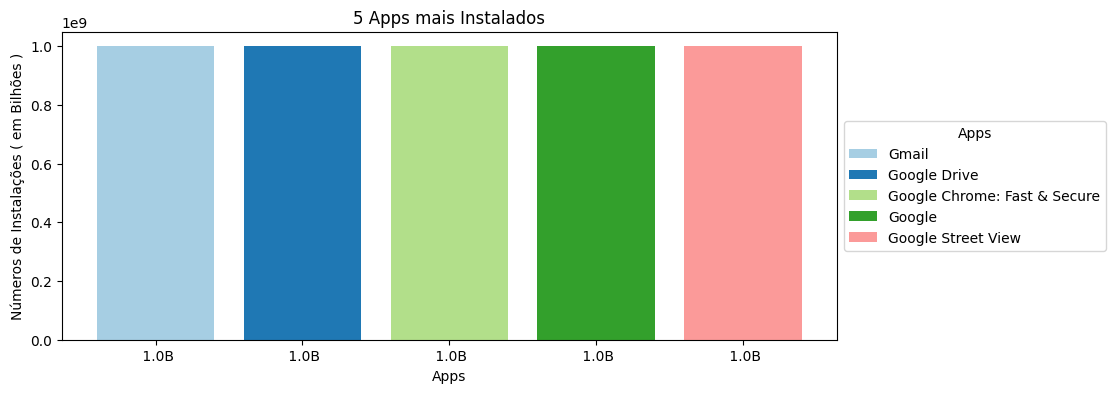

In [536]:
top5 = df[["App","Installs"]].groupby("App", as_index=False).mean().sort_values(by=["Installs"], ascending=False).head(5)


figure, axis = plt.subplots(figsize=(10, 4))

barplot = axis.bar(top5["App"],top5["Installs"],color=plt.cm.Paired.colors)

top5["Label"] = top5["Installs"].apply(lambda x: number_to_text(x))

axis.set_title("5 Apps mais Instalados")
axis.set_xlabel('Apps')
axis.set_ylabel('Números de Instalações ( em Bilhões )')

axis.legend(barplot, top5["App"], title='Apps', loc='center left', bbox_to_anchor=(1, 0.5))

axis.set_xticks(top5["App"])
axis.set_xticklabels(top5["Label"])

plt.show()

## Categorias de Aplicativos

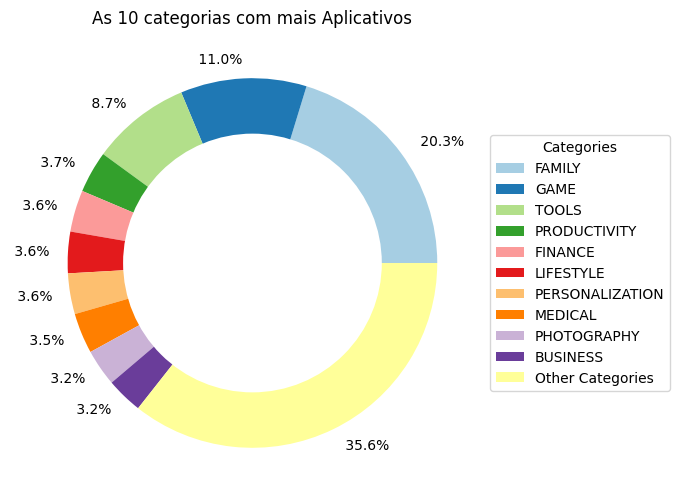

In [537]:
app_categories = df.groupby("Category", as_index=False).count().sort_values(by="App", ascending=False)[["Category","App"]]
number_of_slices = 10


# Ajusts to the Filtered DataFrame
usable_slices = app_categories.head(number_of_slices)
other_categories_quantity = app_categories.tail(-number_of_slices).sum()["App"]
total_quantity = app_categories.sum()["App"]
usable_slices = pd.concat([usable_slices, pd.DataFrame({"Category": ["Other Categories"], "App": [other_categories_quantity]})], ignore_index=True)
usable_slices["Percentage"] = (usable_slices["App"] / total_quantity)
usable_slices["Percentage"] = usable_slices.Percentage.apply(lambda x: int_to_percent(x))

# Ajusts on the Figure/Plot
figure, axis = plt.subplots(figsize=(6, 6)) 
wedges, variable = axis.pie(data=usable_slices, x="App", labels="Percentage", colors=plt.cm.Paired.colors)

# Putting Title and Legend
axis.set_title(f'As {number_of_slices} categorias com mais Aplicativos')
axis.legend(wedges, usable_slices['Category'], title="Categories", loc="center left", bbox_to_anchor=(1, 0.5))

# Center Circle to Figure just to make it more Beauty
centre_circle = plt.Circle((0, 0), 0.70, fc='white')
figure.gca().add_artist(centre_circle)

plt.show()

## App mais Caro

In [538]:
most_price_app = df.sort_values(by="Price", ascending=False).head(1)

most_price_app.head()

,App,Category,Size,Installs,Type,Price,Rating,Content Rating,Genres,Last Updated,Current Ver,Android Ver,Reviews
4418,I'm Rich - Trump Edition,LIFESTYLE,7.3M,10000,Paid,400.0,3.6,Everyone,Lifestyle,"May 3, 2018",1.0.1,4.1 and up,275


## Aplicativos com Restrição de Idade +17

In [539]:
all_mature = df.query("`Content Rating` == 'Mature 17+'")

all_mature.head()

,App,Category,Size,Installs,Type,Price,Rating,Content Rating,Genres,Last Updated,Current Ver,Android Ver,Reviews
1,- Free Comics - Comic Apps,COMICS,9.1M,10000,Free,0.0,3.5,Mature 17+,Comics,"July 13, 2018",5.0.12,5.0 and up,115
3,/u/app,COMMUNICATION,53M,10000,Free,0.0,4.7,Mature 17+,Communication,"July 3, 2018",4.2.4,4.1 and up,573
12,"100000+ Messages - DP, Status, Jokes & GIF 2018",LIFESTYLE,3.8M,10000,Free,0.0,3.7,Mature 17+,Lifestyle,"December 29, 2017",DPSTATUS1.0.1,4.0.3 and up,121
33,211:CK Lite,GAME,39M,10,Free,0.0,4.3,Mature 17+,Action,"September 22, 2017",1.0,4.1 and up,3
36,"2Date Dating App, Love and matching",DATING,8.1M,500000,Free,0.0,4.4,Mature 17+,Dating,"July 26, 2018",4.813,4.0.3 and up,41605


## 10 Aplicativos com mais Reviews

In [540]:
top_10_apps_reviews = df.sort_values(by="Reviews", ascending=False)[["App","Reviews"]].head(10)

top_10_apps_reviews.head(10)

,App,Reviews
4483,Instagram,266241989
7774,WhatsApp Messenger,207348304
5162,Messenger – Text and Video Chat for Free,169932272
6902,Subway Surfers,166331958
3472,Facebook,156286514
2099,Clash of Clans,134677334
1912,Candy Crush Saga,134573681
91,8 Ball Pool,85201288
2095,Clash Royale,69405018
6724,Snapchat,68045010


## Média do tamanho dos Aplicativos

In [541]:
size_mean = df["Size"].apply(lambda x: to_mb(x)).mean()

print(f"Media do tamanho dos aplicativos: {size_mean: .2f}")

Media do tamanho dos aplicativos:  37.40


## Quantidade de Aplicativos Pagos e Gratuitos

In [542]:
count_of_types = df.groupby("Type", as_index=False).count()[["Type","App"]]

count_of_types.head(100)

,Type,App
0,Free,7707
1,Paid,604


## Gráfico Sobre a Quantidade de Aplicativos pagos e gratuitos

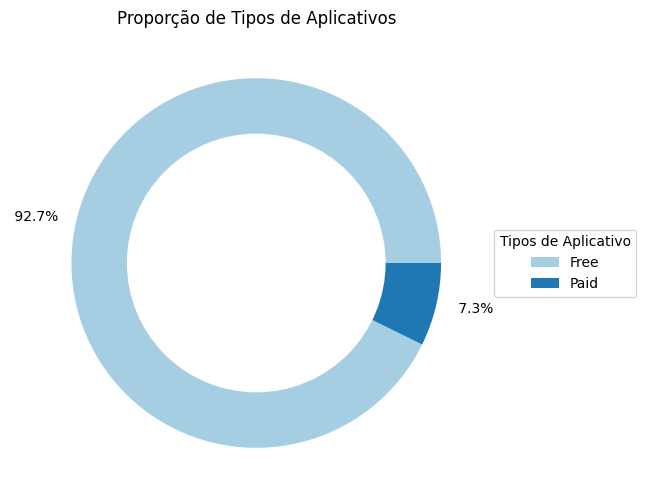

In [543]:
total_quantity = count_of_types.sum()["App"]
count_of_types["Percentage"] = (count_of_types["App"] / total_quantity).apply(lambda x: int_to_percent(x))

# Ajusts on the Figure/Plot
figure, axis = plt.subplots(figsize=(6, 6)) 
wedges, variable = axis.pie(data=count_of_types, x="App", labels="Percentage", colors=plt.cm.Paired.colors)

# Putting Title and Legend
axis.set_title('Proporção de Tipos de Aplicativos')
axis.legend(wedges, count_of_types["Type"], title="Tipos de Aplicativo", loc="center left", bbox_to_anchor=(1, 0.5))

# Center Circle to Figure just to make it more Beauty
centre_circle = plt.Circle((0, 0), 0.70, fc='white')
figure.gca().add_artist(centre_circle)

plt.show()

## Gráfico sobre 10 aplicativos com mais Reviews

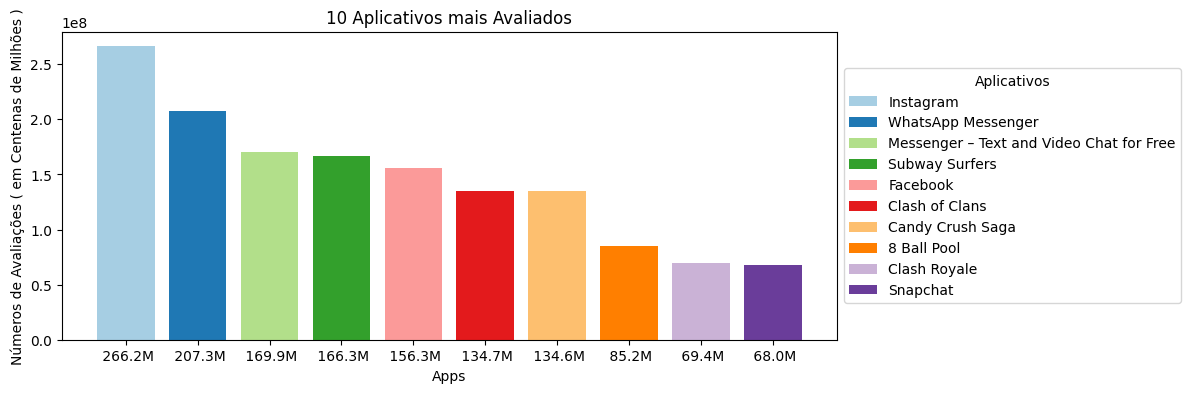

In [544]:
figure, axis = plt.subplots(figsize=(10, 4))

# top_10_apps_reviews["Label"] = None
top_10_apps_reviews["Label"] = top_10_apps_reviews["Reviews"].apply(lambda x: number_to_text(x))

bar_top10 = axis.bar(data=top_10_apps_reviews, x="App" ,height="Reviews", color=plt.cm.Paired.colors)

axis.set_title("10 Aplicativos mais Avaliados")
axis.set_xlabel('Apps')
axis.set_ylabel('Números de Avaliações ( em Centenas de Milhões )')

axis.legend(bar_top10, top_10_apps_reviews["App"], title='Aplicativos', loc='center left', bbox_to_anchor=(1, 0.5))

axis.set_xticks(top_10_apps_reviews["App"])
axis.set_xticklabels(top_10_apps_reviews["Label"])

plt.show()